# Session 29 Solutions: Correlation

Data Science with Python, Level 2, Stage 4: Statistics

Try each exercise yourself before reading its solution. There is usually more than one correct answer; compare your approach with this one.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(29)
DATA_URL = "https://raw.githubusercontent.com/mohammadyahoo/ds-python-course/main/data/"
exams = pd.read_csv(DATA_URL + "exam_scores.csv")
bikes = pd.read_csv(DATA_URL + "bike_rentals.csv")

## In-Class Exercises

### In-Class Exercise 1: Strongest Link

In [2]:
num = exams.select_dtypes("number").drop(columns="student_id")
print(num.corr()["english"].drop("english").sort_values(key=abs, ascending=False).round(3))

study_hours_week    0.446
math                0.199
physics             0.178
attendance_pct      0.064
sleep_hours         0.037
Name: english, dtype: float64


### In-Class Exercise 2: Pearson versus Spearman

-0.048 -0.071


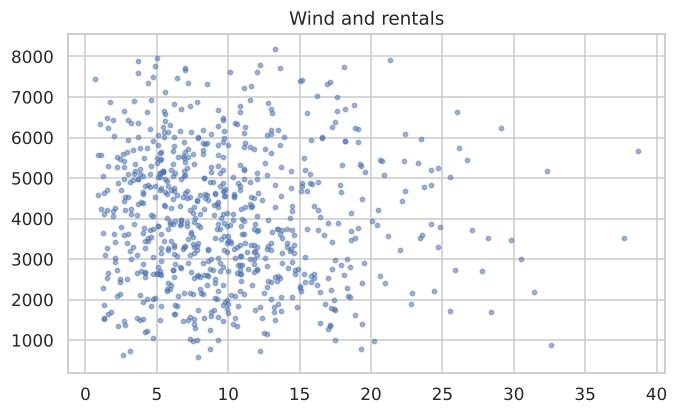

In [3]:
print(round(bikes["wind_kmh"].corr(bikes["rentals"]), 3), round(bikes["wind_kmh"].corr(bikes["rentals"], method="spearman"), 3))
plt.scatter(bikes["wind_kmh"], bikes["rentals"], s=8, alpha=0.5)
plt.title("Wind and rentals")
plt.show()

### In-Class Exercise 3: Confounder Hunt

In [4]:
flats = pd.read_csv(DATA_URL + "apartments.csv")
print(round(flats["distance_center_km"].corr(flats["price_k"]), 3))
for d, g in flats.groupby("district"):
    print(d, round(g["distance_center_km"].corr(g["price_k"]), 3))

-0.457
Hillview -0.003
Northgate -0.106
Old Town -0.051
Riverside -0.007
Westpark 0.088


### In-Class Exercise 4: Spurious by Chance

In [5]:
noise = pd.DataFrame(rng.normal(size=(30, 20)))
c = noise.corr().abs().to_numpy()
pairs = (c[np.triu_indices(20, k=1)] > 0.4).sum()
print(pairs, "of", 20 * 19 // 2, "pairs")

6 of 190 pairs


## Part A: Basic

### Exercise 1: Correlations in the Bike Data

In [6]:
print(bikes[["temp_c", "humidity", "wind_kmh"]].corrwith(bikes["rentals"]).round(3))

temp_c      0.724
humidity   -0.466
wind_kmh   -0.048
dtype: float64


### Exercise 2: Scatter and r

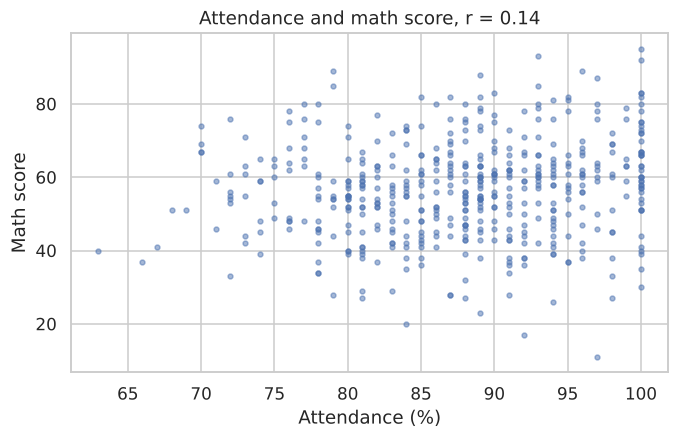

In [7]:
r = exams["attendance_pct"].corr(exams["math"])
plt.scatter(exams["attendance_pct"], exams["math"], s=10, alpha=0.5)
plt.title(f"Attendance and math score, r = {r:.2f}")
plt.xlabel("Attendance (%)")
plt.ylabel("Math score")
plt.show()

## Part B: Intermediate

### Exercise 3: Salary Correlations by City

In [8]:
emp = pd.read_csv(DATA_URL + "employees.csv")
print("All:", round(emp["years_experience"].corr(emp["monthly_salary"]), 3))
for col in ["city", "department"]:
    print(emp.groupby(col).apply(lambda g: round(g["years_experience"].corr(g["monthly_salary"]), 3), include_groups=False))

All: 0.59
city
Amman     0.634
Beirut    0.728
Cairo     0.703
Dubai     0.678
dtype: float64
department
Data           0.741
Engineering    0.679
Finance        0.460
Marketing      0.720
Sales          0.744
Support        0.743
dtype: float64


### Exercise 4: Rank Correlation

0.798 1.0


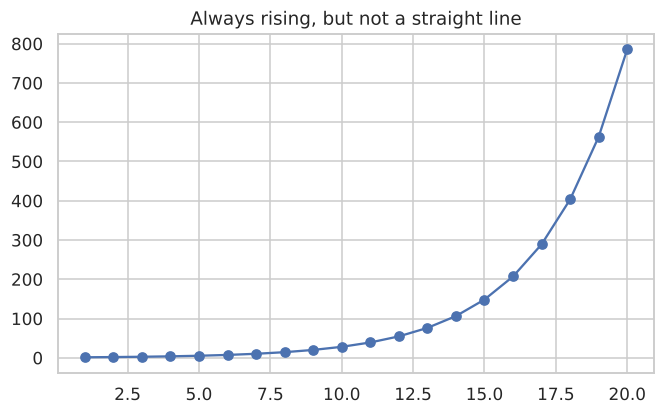

In [9]:
x = np.arange(1, 21)
y = np.exp(x / 3)
print(round(stats.pearsonr(x, y)[0], 3), round(stats.spearmanr(x, y)[0], 3))
plt.plot(x, y, marker="o")
plt.title("Always rising, but not a straight line")
plt.show()
# y always rises with x, so the ranks agree perfectly (Spearman 1); the curve is not a line, so Pearson is lower.

## Part C: Challenge

### Exercise 5: Simpson's Paradox

This reversal is called Simpson's paradox. It is the most dramatic form of confounding.

Overall: 0.863
group
G1   -0.816
G2   -0.916
G3   -0.819
dtype: float64


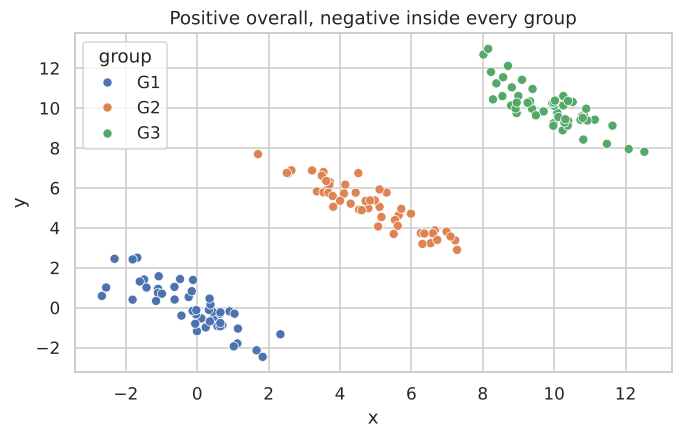

In [10]:
rows = []
for g, (cx, cy) in enumerate([(0, 0), (5, 5), (10, 10)]):
    x = rng.normal(cx, 1.2, 50)
    y = cy - 0.8 * (x - cx) + rng.normal(0, 0.6, 50)
    rows.append(pd.DataFrame({"x": x, "y": y, "group": f"G{g + 1}"}))
d = pd.concat(rows)
print("Overall:", round(d["x"].corr(d["y"]), 3))
print(d.groupby("group").apply(lambda g: round(g["x"].corr(g["y"]), 3), include_groups=False))
sns.scatterplot(data=d, x="x", y="y", hue="group")
plt.title("Positive overall, negative inside every group")
plt.show()

## Part D: Cumulative Project: Exam Scores Study

### Exercise 6: Exam Scores Study: Part 4

[('study_hours_week', 'math', np.float64(0.465)), ('study_hours_week', 'english', np.float64(0.446)), ('study_hours_week', 'physics', np.float64(0.335))]
study_band
(0.299, 3.8]    0.029
(3.8, 6.0]      0.020
(6.0, 9.2]      0.213
(9.2, 22.7]     0.123
dtype: float64


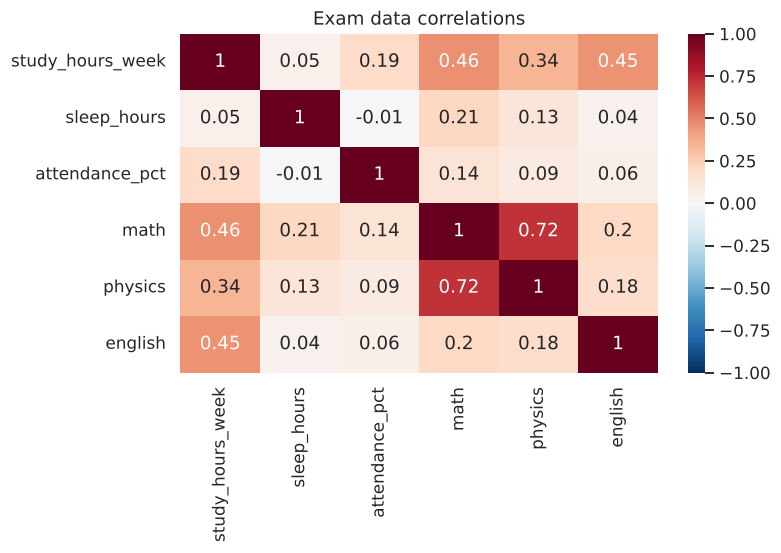

In [11]:
num = exams.select_dtypes("number").drop(columns="student_id")
sns.heatmap(num.corr().round(2), annot=True, cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Exam data correlations")
plt.show()
pairs = [(h, s, round(exams[h].corr(exams[s]), 3)) for h in ["study_hours_week", "sleep_hours", "attendance_pct"]
         for s in ["math", "physics", "english"]]
print(sorted(pairs, key=lambda t: -abs(t[2]))[:3])
exams["study_band"] = pd.qcut(exams["study_hours_week"], 4)
print(exams.groupby("study_band", observed=True).apply(lambda g: round(g["attendance_pct"].corr(g["math"]), 3), include_groups=False))
# Study time has the strongest link with the scores, but the data alone cannot show that studying causes higher scores.
# Comparing the within-band correlations with the overall one shows how much of the attendance link comes from study habits; only an experiment could prove a cause.

## Part E: Quiz Answers

| Question | Answer | Explanation |
| --- | --- | --- |
| 1 | B | Strength is the size of r, whatever its sign. |
| 2 | B | Pearson's r only measures straight-line patterns. |
| 3 | C | Summer heat is a confounder that drives both. |
| 4 | B | Spearman works on ranks. |
| 5 | C | Random assignment removes confounders. |